In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
from google.colab import files

In [2]:
os.makedirs('images', exist_ok=True)

print("Please Upload The Required Images:")
print("- img_15.jpg")
print("- img_2.5.jpg")
print("- img_0.25.jpg")
print("- img_0.033.jpg")
print("- 1280px-HDRI_Sample_Scene_Window_-_10.jpg")
print("- 1280px-HDRI_Sample_Scene_Window_-_05.jpg")

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"Uploaded: {filename}")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Please Upload The Required Images:
- img_15.jpg
- img_2.5.jpg
- img_0.25.jpg
- img_0.033.jpg
- 1280px-HDRI_Sample_Scene_Window_-_10.jpg
- 1280px-HDRI_Sample_Scene_Window_-_05.jpg


Saving 1280px-HDRI_Sample_Scene_Window_-_05.jpg to 1280px-HDRI_Sample_Scene_Window_-_05.jpg
Saving 1280px-HDRI_Sample_Scene_Window_-_10.jpg to 1280px-HDRI_Sample_Scene_Window_-_10.jpg
Saving img_0.25.jpg to img_0.25.jpg
Saving img_0.033.jpg to img_0.033.jpg
Saving img_2.5.jpg to img_2.5.jpg
Saving img_15.jpg to img_15.jpg
Uploaded: 1280px-HDRI_Sample_Scene_Window_-_05.jpg
Uploaded: 1280px-HDRI_Sample_Scene_Window_-_10.jpg
Uploaded: img_0.25.jpg
Uploaded: img_0.033.jpg
Uploaded: img_2.5.jpg
Uploaded: img_15.jpg

Contents Of Images Folder:
['img_0.25.jpg', '1280px-HDRI_Sample_Scene_Window_-_05.jpg', 'img_2.5.jpg', 'img_15.jpg', 'img_0.033.jpg', '1280px-HDRI_Sample_Scene_Window_-_10.jpg']


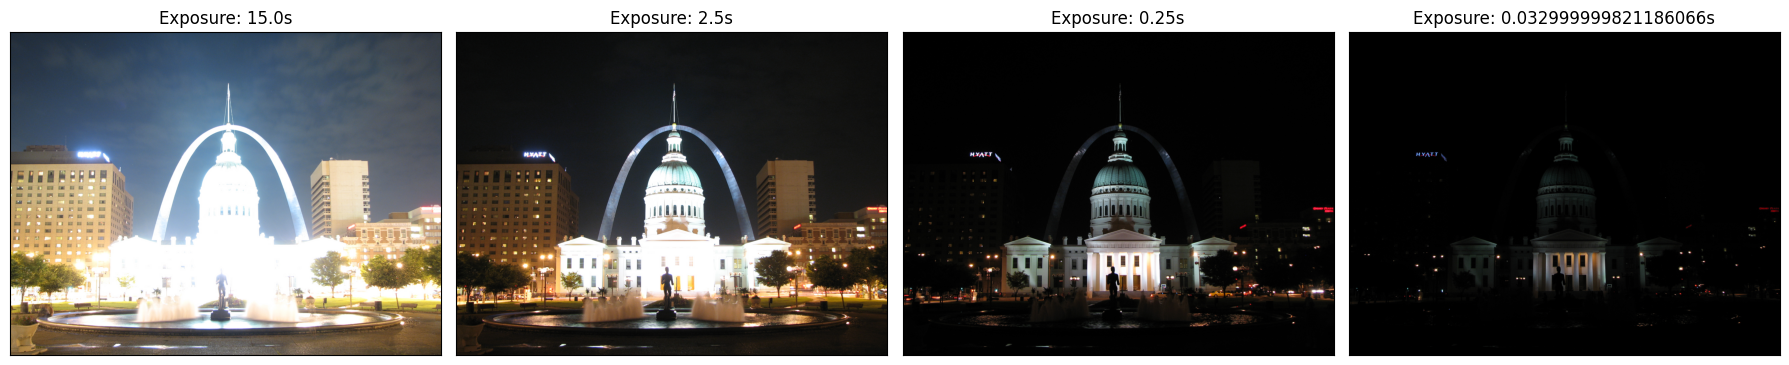

In [5]:
img_fn = ["images/img_15.jpg", "images/img_2.5.jpg", "images/img_0.25.jpg", "images/img_0.033.jpg"]
img_list = [cv2.imread(fn) for fn in img_fn]
exposure_times = np.array([15.0, 2.5, 0.25, 0.033], dtype=np.float32)

plt.figure(figsize=(18, 4))

for i, (image, exposure) in enumerate(zip(img_list, exposure_times)):
  plt.subplot(1, 4, i + 1)
  plt.imshow(image[..., ::-1])
  plt.title(f"Exposure: {exposure}s")
  plt.xticks([])
  plt.yticks([])

plt.tight_layout()
plt.show()

In [6]:
merge_mertens = cv2.createMergeMertens()
hdr_mertens = merge_mertens.process(img_list)

In [7]:
res_mertens = np.clip(hdr_mertens * 255, 0, 255).astype('uint8')

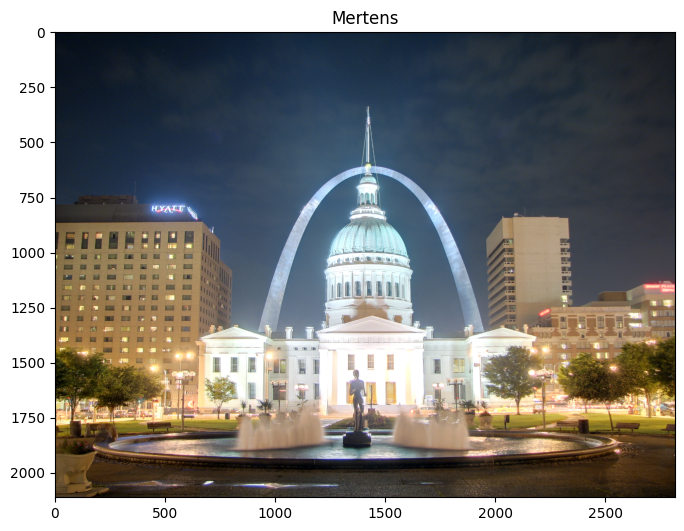

In [8]:
plt.figure(figsize=(8, 8))

plt.imshow(res_mertens[..., ::-1])
plt.title("Mertens")

plt.show()

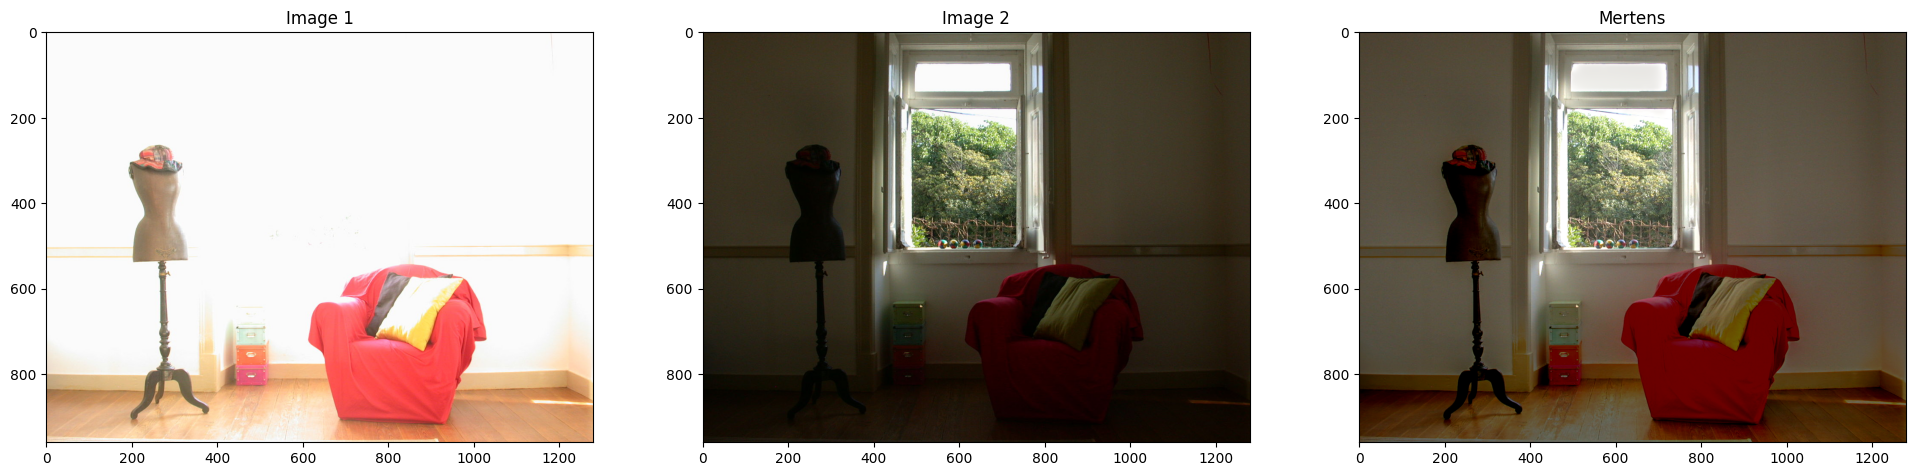

In [9]:
images = ['images/1280px-HDRI_Sample_Scene_Window_-_10.jpg','images/1280px-HDRI_Sample_Scene_Window_-_05.jpg']
images = [cv2.imread(img) for img in images]

merge = cv2.createMergeMertens()
hdr = merge.process(images)

res = np.clip(hdr * 255, 0, 255).astype('uint8')

plt.figure(figsize=(24, 8))

plt.subplot(1, 3, 1)
plt.imshow(images[0][..., ::-1])
plt.title("Image 1")

plt.subplot(1, 3, 2)
plt.imshow(images[1][..., ::-1])
plt.title("Image 2")

plt.subplot(1, 3, 3)
plt.imshow(res[..., ::-1])
plt.title("Mertens")

plt.show()

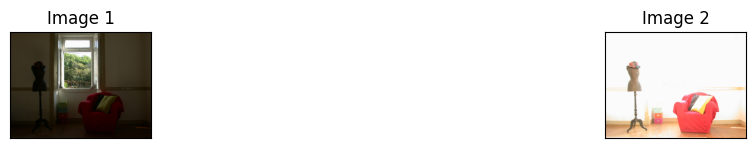

In [10]:
images = glob.glob('images/1280px-HDRI_Sample_Scene_Window_-*.jpg')
img_list = [cv2.imread(img) for img in images]

plt.figure(figsize=(18, 4))

for i, image in enumerate(img_list):
  plt.subplot(3, 3, i + 1)
  plt.imshow(image[..., ::-1])
  plt.title(f"Image {i + 1}")
  plt.xticks([])
  plt.yticks([])

plt.tight_layout()
plt.show()

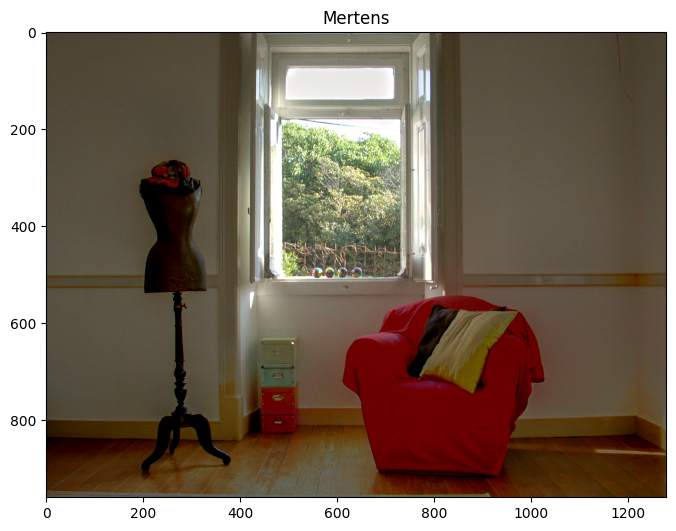

In [11]:
merge_mertens = cv2.createMergeMertens()
hdr_mertens = merge_mertens.process(img_list)

res_mertens = np.clip(hdr_mertens * 255, 0, 255).astype('uint8')

plt.figure(figsize=(8, 8))

plt.imshow(res_mertens[..., ::-1])
plt.title("Mertens")

plt.show()